<a href="https://colab.research.google.com/github/ryeggouti/morocco-drought/blob/main/morocco_drought.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Is Morocco Running Out of Rain?
**Not exactly. It's getting hotter.**

This notebook analyses 34 rainy seasons (1991/92–2024/25) on a grid of 62 points covering all of Morocco, including its southern provinces, and tests which changes are statistically real.

**Website:** https://ryeggouti.github.io/morocco-drought/ · Part of *Morocco in Data* (see also [How Did Morocco Reach the Semi-Final?](https://ryeggouti.github.io/morocco-world-cup-2022/))

## Results at a glance
| Question | Answer | Evidence |
|---|---|---|
| Is rainfall declining? | No clear trend | −0.4 mm per decade, p = 0.96 |
| Is the recent decade drier? | Slightly, but could be chance | 182 → 169 mm per season, p = 0.31 |
| When was the last very wet season? | 2014/15 | 10 seasons since; record gap is 12 (1996/97–2007/08) |
| Which region lost the most? | The centre | −14.0% (about −33 mm), p = 0.098 |
| Is evaporation demand rising? | Yes, strongly | +31.2 mm per decade, p = 0.001 |
| Is the water balance worsening? | Yes, just significant | −31.6 mm per decade, p = 0.047 |
| Does rain drive harvests? | Yes | r = 0.61 with cereal yield, p = 0.0001 (33 seasons) |

## How to run
Run the cells from top to bottom. Downloading all the data from Open-Meteo takes a while and can hit its free hourly limit, so section 3 **saves after every point and resumes** where it stopped. If you already have `morocco_rain_grid.csv` and `morocco_et0_grid.csv`, upload them first and the downloads are skipped.

## 1. Setup

In [1]:
!pip install geopandas -q
import os, json, glob, time, requests
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
from scipy import stats

RED, GREY, BLUE = "#C1272D", "#8A8F8C", "#4a90c2"

## 2. The grid
One point every 1° (about 100 km), kept only if it falls inside Morocco's border. Natural Earth draws Morocco and its southern provinces as two shapes, so they are joined.

In [2]:
url = "https://naciscdn.org/naturalearth/50m/cultural/ne_50m_admin_0_countries.zip"
world = gpd.read_file(url)
names = ["Morocco", "Western Sahara"]
shapes = world[world.ADMIN.isin(names)].geometry
if hasattr(shapes, "union_all"):
    morocco = shapes.union_all()
else:
    morocco = shapes.unary_union

grid = []
for lat in range(20, 36):
    for lon in range(-18, -1):
        p = (lat + 0.5, lon + 0.5)
        if morocco.contains(Point(p[1], p[0])):
            grid.append(p)
print(len(grid), "grid points")

62 grid points


## 3. Data: daily rain and evaporation demand
Source: Open-Meteo historical archive (reanalysis: observations combined with a model, not single weather stations).
- `precipitation_sum`: rain, in mm per day
- `et0_fao_evapotranspiration`: **evaporation demand**, how much water the air would take from soil and plants if it could

The download saves each point to a CSV as soon as it arrives, so it can be stopped and resumed. During the original run, the free API's hourly limit blocked the 7 northernmost points, so they were downloaded by hand as JSON files (`archive*.json`) and merged in with `merge_json`.

In [3]:
API = "https://archive-api.open-meteo.com/v1/archive"

def fetch(lat, lon, var):
    params = {"latitude": lat, "longitude": lon,
              "start_date": "1991-01-01", "end_date": "2025-12-31",
              "daily": var, "timezone": "Africa/Casablanca"}
    while True:
        data = requests.get(API, params=params, timeout=90).json()
        if "daily" in data:
            return pd.DataFrame(data["daily"])
        print("Rate limited, waiting 5 minutes...")
        time.sleep(300)

def saved_points(path):
    if not os.path.exists(path):
        return set()
    old = pd.read_csv(path, usecols=["lat", "lon"])
    return set(zip(old.lat, old.lon))

def download(path, var):
    done = saved_points(path)
    for lat, lon in grid:
        if (lat, lon) in done:
            continue
        d = fetch(lat, lon, var)
        d["lat"], d["lon"] = lat, lon
        header = not os.path.exists(path)
        d.to_csv(path, mode="a", index=False, header=header)
        done.add((lat, lon))
        print(len(done), "/", len(grid))
        time.sleep(8)

def merge_json(path, var):
    # Adds points downloaded by hand (archive*.json) to the CSV
    need = [p for p in grid if p not in saved_points(path)]
    for fname in glob.glob("archive*.json"):
        data = json.load(open(fname))
        if isinstance(data, dict):
            continue
        for res in data:
            if var not in res["daily"] or not need:
                continue
            dist = lambda p: (p[0] - res["latitude"]) ** 2 + (p[1] - res["longitude"]) ** 2
            lat, lon = min(need, key=dist)
            d = pd.DataFrame(res["daily"])
            d["lat"], d["lon"] = lat, lon
            d.to_csv(path, mode="a", index=False, header=False)
            need.remove((lat, lon))

In [4]:
RAIN_FILE = "morocco_rain_grid.csv"
ET_FILE = "morocco_et0_grid.csv"

merge_json(RAIN_FILE, "precipitation_sum")
merge_json(ET_FILE, "et0_fao_evapotranspiration")
download(RAIN_FILE, "precipitation_sum")
download(ET_FILE, "et0_fao_evapotranspiration")

def load(path, var):
    d = pd.read_csv(path)[["time", var, "lat", "lon"]]
    d["time"] = pd.to_datetime(d["time"])
    return d.drop_duplicates(subset=["lat", "lon", "time"])

rain = load(RAIN_FILE, "precipitation_sum")
et = load(ET_FILE, "et0_fao_evapotranspiration")
for name, d in [("Rain", rain), ("Evaporation", et)]:
    n = d[["lat", "lon"]].drop_duplicates().shape[0]
    print(name, ":", n, "of", len(grid), "points,", len(d), "rows")

Rain : 62 of 62 points, 792608 rows
Evaporation : 62 of 62 points, 792608 rows


## 4. From days to rainy seasons
Morocco's rain falls mostly from September to April, so a calendar year would cut each rainy season in half. Farmers and the government measure by **agricultural season** (September to August), so this notebook does too: September 2022 to August 2023 is season "2022/23". Only complete seasons are kept (1991/92 to 2024/25).

The national value for a season is the average of the 62 points' seasonal totals.

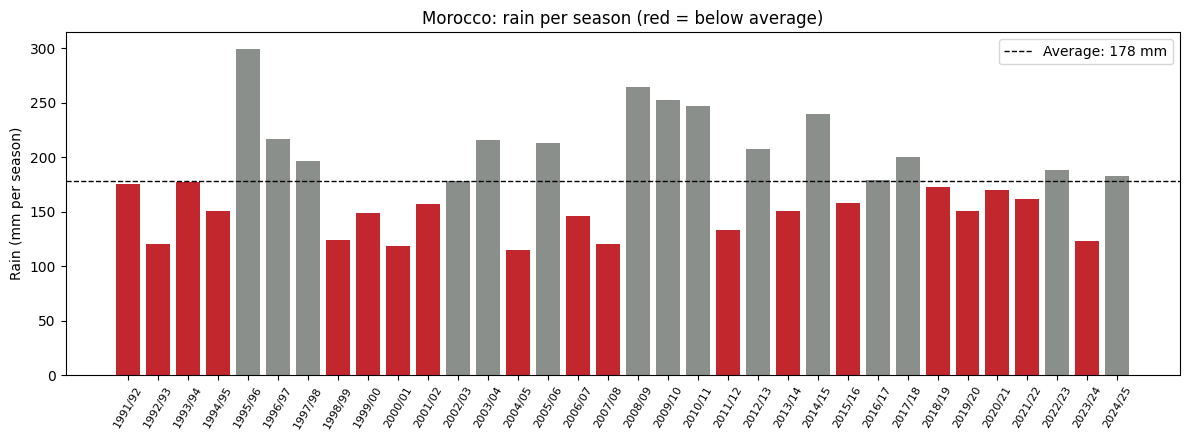

In [5]:
both = rain.merge(et, on=["lat", "lon", "time"])
month, year = both["time"].dt.month, both["time"].dt.year
both["season"] = year.where(month >= 9, year - 1)
both = both[(both.season >= 1991) & (both.season <= 2024)]

cols = ["precipitation_sum", "et0_fao_evapotranspiration"]
per_point = both.groupby(["lat", "lon", "season"])[cols].sum().reset_index()
per_point.columns = ["lat", "lon", "season", "rain", "et0"]
per_point["balance"] = per_point.rain - per_point.et0

nat = per_point.groupby("season")[["rain", "et0", "balance"]].mean()
avg = nat.rain.mean()
pct = nat.rain / avg * 100
labels = [f"{s}/{str(s + 1)[2:]}" for s in nat.index]

plt.figure(figsize=(12, 4.5))
colors = [RED if v < avg else GREY for v in nat.rain]
plt.bar(labels, nat.rain, color=colors)
plt.axhline(avg, color="black", linestyle="--", linewidth=1,
            label=f"Average: {avg:.0f} mm")
plt.xticks(rotation=60, fontsize=8)
plt.ylabel("Rain (mm per season)")
plt.title("Morocco: rain per season (red = below average)")
plt.legend()
plt.tight_layout()
plt.show()

## Finding 1: the wet years stopped
A season counts as **very wet** if it brought 25% or more above the 34-season average. To make sure the result doesn't depend on one threshold, the table counts seasons at 15%, 25% and 35% in three periods of similar length.

In [6]:
print("Very wet seasons (25%+ above average):")
for lab, v in zip(labels, pct):
    if v >= 125:
        print(" ", lab, f"{v:.0f}%")

periods = {"1991/92-2002/03": (1991, 2002),
           "2003/04-2013/14": (2003, 2013),
           "2014/15-2024/25": (2014, 2024)}
rows = []
for name, (a, b) in periods.items():
    p = pct[(pct.index >= a) & (pct.index <= b)]
    rows.append({"period": name,
                 "15%+": int((p >= 115).sum()),
                 "25%+": int((p >= 125).sum()),
                 "35%+": int((p >= 135).sum()),
                 "below avg": int((p < 100).sum())})
print(pd.DataFrame(rows).to_string(index=False))

run, best, best_end = 0, 0, None
for s, v in pct.items():
    run = 0 if v >= 125 else run + 1
    if run > best:
        best, best_end = run, s
print("Current run without a very wet season:", run)
print("Longest run:", best, "seasons, ending", best_end)
print("Five driest seasons:", sorted(pct.nsmallest(5).index.tolist()))

Very wet seasons (25%+ above average):
  1995/96 168%
  2008/09 149%
  2009/10 142%
  2010/11 139%
  2014/15 134%
         period  15%+  25%+  35%+  below avg
1991/92-2002/03     2     1     1          8
2003/04-2013/14     6     3     3          5
2014/15-2024/25     1     1     0          6
Current run without a very wet season: 10
Longest run: 12 seasons, ending 2007
Five driest seasons: [1992, 2000, 2004, 2007, 2023]


**Result:** the very wet seasons were 1995/96, 2008/09, 2009/10, 2010/11 and 2014/15. None since: 10 seasons, the second-longest gap since 1991 (the longest was 12, 1996/97–2007/08). The five driest seasons were all in 2007/08 or earlier, so the recent decade is not record-dry. It is missing the wet years that used to refill reservoirs.

## Finding 2: the centre lost the most
For each point: average rain per season in 2015–2025 compared with 1991–2015. Regions are averaged **weighted by normal rainfall**, because a 30% change in the desert is only a few millimetres, while the wetter regions supply Morocco's rivers and dams. A Welch t-test checks whether each region's recent seasons differ from the earlier ones by more than chance.

South: 28 points, 37 mm normal, +13.5% (+5 mm), p = 0.579
Centre: 22 points, 239 mm normal, -14.0% (-33 mm), p = 0.098
North: 12 points, 416 mm normal, -4.7% (-19 mm), p = 0.550
National: 182 -> 169 mm, p = 0.306


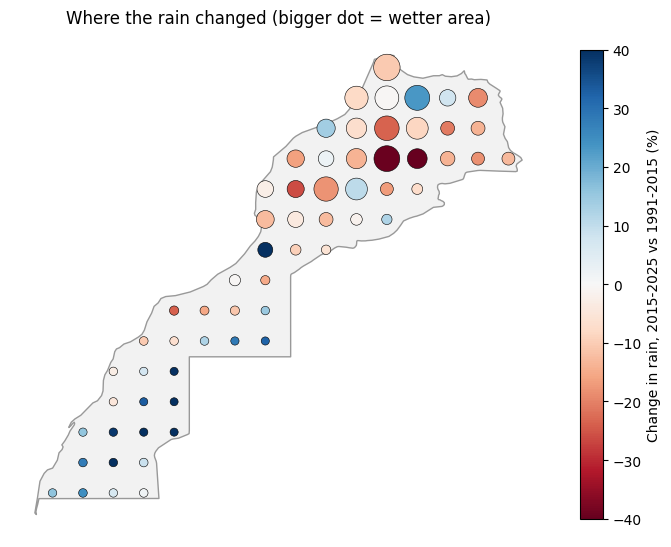

In [7]:
early = per_point[per_point.season <= 2014]
late = per_point[per_point.season >= 2015]
change = pd.DataFrame({
    "before": early.groupby(["lat", "lon"]).rain.mean(),
    "recent": late.groupby(["lat", "lon"]).rain.mean(),
}).reset_index()
change["pct"] = (change.recent - change.before) / change.before * 100
change["region"] = pd.cut(change.lat, bins=[0, 29, 33, 40],
                          labels=["South", "Centre", "North"])

for region, g in change.groupby("region", observed=True):
    w = (g.pct * g.before).sum() / g.before.sum()
    mm = (g.recent - g.before).mean()
    pts = per_point.merge(g[["lat", "lon"]], on=["lat", "lon"])
    series = pts.groupby("season").rain.mean()
    t = stats.ttest_ind(series.loc[2015:], series.loc[:2014], equal_var=False)
    print(f"{region}: {len(g)} points, {g.before.mean():.0f} mm normal, "
          f"{w:+.1f}% ({mm:+.0f} mm), p = {t.pvalue:.3f}")

t = stats.ttest_ind(nat.rain.loc[2015:], nat.rain.loc[:2014], equal_var=False)
print(f"National: {nat.rain.loc[:2014].mean():.0f} -> "
      f"{nat.rain.loc[2015:].mean():.0f} mm, p = {t.pvalue:.3f}")

fig, ax = plt.subplots(figsize=(7, 7))
gpd.GeoSeries([morocco]).plot(ax=ax, color="#f2f2f2", edgecolor="#999999")
sc = ax.scatter(change.lon, change.lat, c=change.pct, cmap="RdBu",
                vmin=-40, vmax=40, s=change.before / 2 + 20,
                edgecolors="black", linewidths=0.4)
plt.colorbar(sc, label="Change in rain, 2015-2025 vs 1991-2015 (%)", shrink=0.7)
ax.set_title("Where the rain changed (bigger dot = wetter area)")
ax.set_axis_off()
plt.tight_layout()
plt.show()

**Result:** the centre (29–33°N: Marrakech, Beni Mellal, the Atlas) lost about 14% of its seasonal rain (about −33 mm), the north about 5% (−19 mm), while the desert south gained about 14%, which is only about +5 mm. None of these changes is statistically significant; the centre's (p ≈ 0.10) is the closest. Nationally, 182 → 169 mm per season (p = 0.31) could be chance.

## Finding 3: the thirsty air
If rain hasn't clearly fallen, why does the water crisis feel worse? **Evaporation demand** rises with heat, sunshine and dry air. A linear trend over all 34 seasons, with its p-value, shows which quantity is really changing.

Trend per decade:
  rain: -0.4 mm, p = 0.960
  et0: +31.2 mm, p = 0.001
  balance: -31.6 mm, p = 0.047
Since 2015: rain -13 mm, evaporation demand +59 mm
Share of the worsening balance due to evaporation: 82%


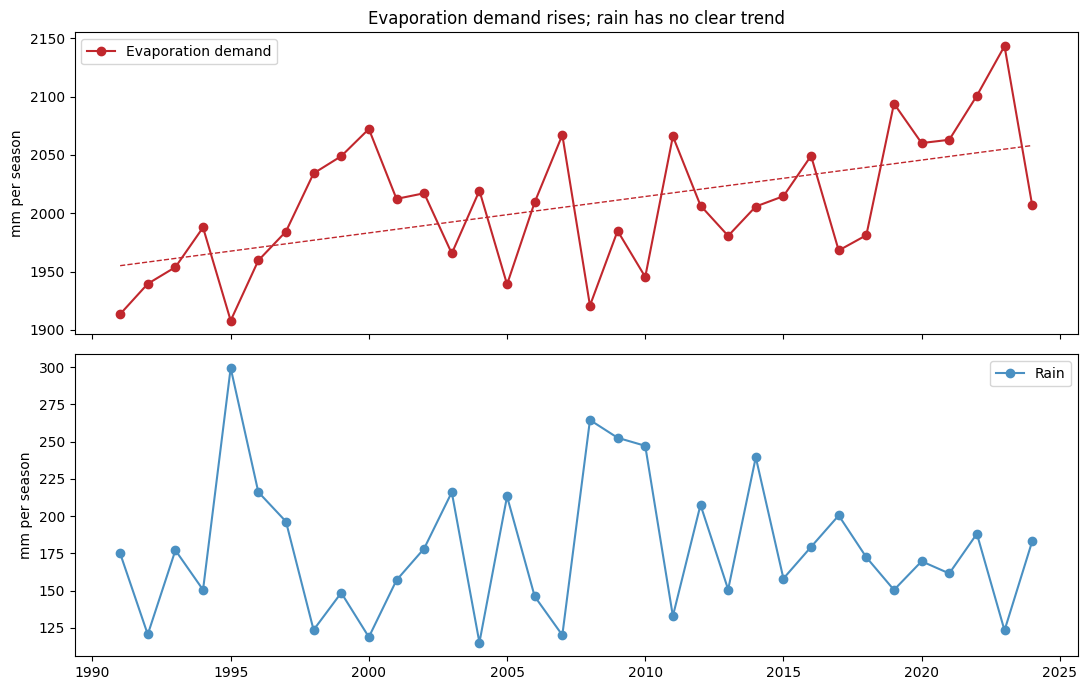

In [8]:
xs = nat.index.values
print("Trend per decade:")
for col in ["rain", "et0", "balance"]:
    r = stats.linregress(xs, nat[col])
    print(f"  {col}: {r.slope * 10:+.1f} mm, p = {r.pvalue:.3f}")

e, l = nat.loc[:2014].mean(), nat.loc[2015:].mean()
d_rain, d_et0 = l.rain - e.rain, l.et0 - e.et0
share = d_et0 / (d_et0 - d_rain) * 100
print(f"Since 2015: rain {d_rain:+.0f} mm, evaporation demand {d_et0:+.0f} mm")
print(f"Share of the worsening balance due to evaporation: {share:.0f}%")

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(xs, nat.et0, color=RED, marker="o", label="Evaporation demand")
fit = np.polyfit(xs, nat.et0, 1)
ax[0].plot(xs, np.polyval(fit, xs), color=RED, linestyle="--", linewidth=1)
ax[0].set_ylabel("mm per season")
ax[0].legend()
ax[0].set_title("Evaporation demand rises; rain has no clear trend")
ax[1].plot(xs, nat.rain, color=BLUE, marker="o", label="Rain")
ax[1].set_ylabel("mm per season")
ax[1].legend()
plt.tight_layout()
plt.show()

**Result:** evaporation demand rose about +31 mm per decade (p = 0.001), while rain changed by about −0.4 mm per decade (p = 0.96). The water balance (rain minus evaporation demand) worsened about −32 mm per decade (p = 0.047). Since 2015, roughly 80% of the worsening comes from higher evaporation demand, not from less rain.

*Caveat:* evaporation demand is what the air **could** take. When soil is already dry, actual evaporation is lower, so this measures pressure on the water supply, not water actually lost.

## Finding 4: rain decides the harvest
A real-world check. Most of Morocco's cereals are rain-fed, so if this rainfall data is accurate, dry seasons should match bad harvests. Cereal yield (kg per hectare) comes from the World Bank (indicator `AG.YLD.CREL.KG`). The harvest is in May–June, so season 2022/23 is matched to the 2023 harvest.

33 seasons, r = 0.61, p = 0.0001
Rain explains about 38% of harvest swings


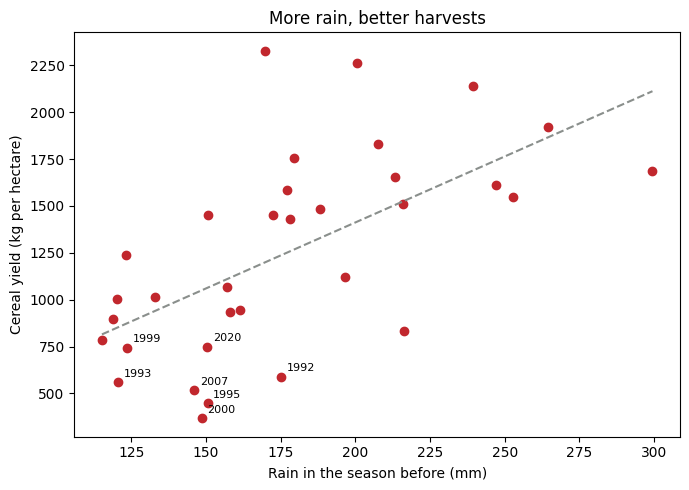

In [9]:
wb = ("https://api.worldbank.org/v2/country/MAR/indicator/"
      "AG.YLD.CREL.KG?format=json&per_page=100")
rows = requests.get(wb, timeout=60).json()[1]
yld = pd.Series({int(r["date"]): r["value"] for r in rows if r["value"]})

harvest = pd.DataFrame({"rain": nat.rain.values}, index=nat.index + 1)
harvest["yield"] = yld
harvest = harvest.dropna()
r = stats.pearsonr(harvest.rain, harvest["yield"])
print(f"{len(harvest)} seasons, r = {r.statistic:.2f}, p = {r.pvalue:.4f}")
print(f"Rain explains about {r.statistic ** 2 * 100:.0f}% of harvest swings")

plt.figure(figsize=(7, 5))
plt.scatter(harvest.rain, harvest["yield"], color=RED)
for yr, row in harvest.iterrows():
    if row["yield"] < harvest["yield"].quantile(0.2):
        plt.annotate(str(yr), (row.rain, row["yield"]), fontsize=8,
                     xytext=(4, 4), textcoords="offset points")
fit = np.polyfit(harvest.rain, harvest["yield"], 1)
x = np.linspace(harvest.rain.min(), harvest.rain.max(), 50)
plt.plot(x, np.polyval(fit, x), color=GREY, linestyle="--")
plt.xlabel("Rain in the season before (mm)")
plt.ylabel("Cereal yield (kg per hectare)")
plt.title("More rain, better harvests")
plt.tight_layout()
plt.show()

**Result:** r = 0.61 (p = 0.0001) over 33 seasons: rain explains roughly 37% of the year-to-year swings in cereal yield, and the worst harvests followed dry seasons. Points below the line show that totals hide timing: in 2020 the rains came late and January–March heat hurt the crops (FAO). Yields also rose over time with better farming, which a future version could remove before testing.

## 5. Export for the website
The site (`index.html`) reads every number from `rain_data.json`, so nothing on the page is typed in by hand.

In [10]:
trend = {}
for col in ["rain", "et0", "balance"]:
    t = stats.linregress(nat.index, nat[col])
    trend[col] = {"slope": round(float(t.slope) * 10, 1),
                  "p": round(float(t.pvalue), 3)}

seasons = []
for s, row in nat.iterrows():
    h = yld.get(int(s) + 1)
    seasons.append({"season": int(s),
                    "rain": round(float(row.rain), 1),
                    "et0": round(float(row.et0), 1),
                    "harvest": None if pd.isna(h) else float(h)})

points = []
for p in change.itertuples():
    points.append({"lat": float(p.lat), "lon": float(p.lon),
                   "before": round(float(p.before), 1),
                   "recent": round(float(p.recent), 1),
                   "change": round(float(p.pct), 1)})

out = {"seasons": seasons, "points": points, "trend": trend}
with open("rain_data.json", "w") as f:
    json.dump(out, f)
print(len(points), "points,", len(seasons), "seasons")
print(trend)

62 points, 34 seasons
{'rain': {'slope': -0.4, 'p': 0.96}, 'et0': {'slope': 31.2, 'p': 0.001}, 'balance': {'slope': -31.6, 'p': 0.047}}


## Data notes
- Open-Meteo data is reanalysis, not readings from one weather station per city.
- The grid covers Morocco including its southern provinces, using Natural Earth's borders. National figures average all 62 points equally; regional figures are weighted by normal rainfall.
- Seasons run September to August; only complete seasons (1991/92–2024/25) are used.
- p-values below 0.05 are treated as statistically significant. With 34 seasons and large year-to-year swings, some real changes may not reach that bar, so non-significant results are described as patterns, not proven trends.
- I used AI tools to help write some of the code. I chose the questions, checked the results and wrote the findings.